In [1]:
import io, contextlib, warnings, json, urllib.request
from fractions import Fraction
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.signal import butter, filtfilt, resample_poly, find_peaks, detrend
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
import kagglehub
from kagglehub import KaggleDatasetAdapter
import wfdb

C:\Users\Admin\AppData\Local\anaconda3\envs\ml-projects\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
warnings.simplefilter("ignore")
plt.rcParams["figure.dpi"] = 110
RNG = np.random.default_rng(42)

In [3]:
from pathlib import Path

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Загрузка данных

акции Apple

In [4]:
df_apple = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "anukaggle81/usa-top-900-historic-dataset",
    "Apple.csv",
)
df_apple = df_apple.drop(columns=["Unnamed: 0"])
df_apple["Date"] = pd.to_datetime(df_apple["Date"])
df_apple = df_apple.sort_values("Date").reset_index(drop=True)

apple = df_apple["Close"].tail(1000).to_numpy(dtype=float)
print("Apple:", apple.shape)

Apple: (1000,)


MTA Subway Hourly Ridership (NYC)

In [5]:
url = "https://github.com/xinychen/integers/raw/main/Manhattan-subway/NYC_subway_mob_24.npz"
urllib.request.urlretrieve(url, DATA_DIR / "NYC_subway_mob_24.npz")
tensor = np.load(DATA_DIR / "NYC_subway_mob_24.npz")["arr_0"]
hourly_total = tensor.sum(axis=0)

subway = hourly_total[: 24 * 319].astype(float)
print("Subway:", subway.shape, "min =", subway[-1000:].min())

Subway: (7656,) min = 1973.0


записи ЭКГ

In [6]:
FANTASIA_DIR = DATA_DIR / "fantasia"
if not (FANTASIA_DIR / "f1y01.dat").exists():
    wfdb.dl_database("fantasia", str(FANTASIA_DIR), records=["f1y01"], annotators=["ecg"])
record = wfdb.rdrecord(str(FANTASIA_DIR / "f1y01"))
FS = record.fs
ecg_full = record.p_signal[:, record.sig_name.index("ECG")]

start_idx = 60000
ecg = ecg_full[start_idx:start_idx + 1600].astype(float)
print("ECG:", ecg.shape, "fs =", FS)

ECG: (1600,) fs = 250


# Вспомогательные функции

* zscore - z-нормировка ряда: вычитаем среднее и делим на стандартное отклонение. Ряды разного масштаба (например, пассажиропоток и температура) становятся сопоставимы на одном графике, а корреляция и расстояния в CCM и DTW не зависят от единиц измерения
* adf_p - p-value теста ADF (H0: есть единичный корень). Нужен как проверка перед тестом Грейнджера и CCF: на нестационарных рядах общий тренд дает ложную корреляцию
* cross_corr - кросс-корреляционная функция r(k) = corr(x_t, y_{t+k}) для сдвигов от -max_lag до max_lag
* granger_pvals - тест Грейнджера «cause -> effect» для порядков 1…max_lag. Проверяет, улучшают ли прошлые значения cause прогноз effect по сравнению с прогнозом только по прошлому самого effect (F-тест, H0: не улучшают)
* embed - теневое многообразие по теореме Такенса: каждая точка - вектор из E запаздывающих значений ряда с шагом tau. Оно восстанавливает состояние системы по одному наблюдаемому ряду
* ccm - Convergent Cross Mapping. Если cause влияет на effect, то информация о cause записана в динамике effect, и cause можно восстановить по соседям на теневом многообразии effect. Признак причинности - корреляция ρ между восстановленным и настоящим cause, которая растет и выходит на плато с ростом размера библиотеки L (сходимость) Параметры функции:
1. lag - сдвиг, на который восстанавливаем cause, нужен для оценки задержки влияния;
2. exclusion - окно Тейлера, исключает соседей, близких по времени, иначе на гладких рядах ρ завышается за счет автокорреляции;
3. n_samples - число случайных библиотек для каждого L, по ним ρ усредняется
* choose_E - размерность вложения E: перебираем E от 1 до 8 и берем ту, при которой simplex-прогноз ряда на шаг вперед по собственному многообразию дает максимальный ρ

In [7]:
def zscore(x):
    x = np.asarray(x, float)
    return (x - x.mean()) / x.std()


def adf_p(x):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return adfuller(x, autolag="AIC")[1]


def cross_corr(x, y, max_lag):
    x, y = zscore(x), zscore(y)
    n = len(x)
    lags = np.arange(-max_lag, max_lag + 1)
    r = np.empty(len(lags))
    for i, k in enumerate(lags):
        a, b = (x[:n - k], y[k:]) if k >= 0 else (x[-k:], y[:n + k])
        r[i] = np.corrcoef(a, b)[0, 1]
    return lags, r


def granger_pvals(cause, effect, max_lag):
    data = np.column_stack([effect, cause])
    with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
        warnings.simplefilter("ignore")
        res = grangercausalitytests(data, maxlag=max_lag)
    return np.array([res[l][0]["ssr_ftest"][1] for l in range(1, max_lag + 1)])


def embed(x, E, tau):
    n = len(x) - (E - 1) * tau
    return np.column_stack([x[(E - 1 - i) * tau:(E - 1 - i) * tau + n] for i in range(E)])


def ccm(cause, effect, E, tau=1, lib_sizes=None, lag=0, n_samples=20, exclusion=0, seed=0):
    cause, effect = np.asarray(cause, float), np.asarray(effect, float)
    M = embed(effect, E, tau)
    t = np.arange((E - 1) * tau, len(effect))
    ti = t + lag
    ok = (ti >= 0) & (ti < len(cause))
    M, t, target = M[ok], t[ok], cause[ti[ok]]
    n = len(M)
    if lib_sizes is None:
        lib_sizes = [n]
    rng = np.random.default_rng(seed)
    out = []
    for L in lib_sizes:
        L = int(min(L, n))
        rhos = []
        for _ in range(n_samples if L < n else 1):
            lib = np.sort(rng.choice(n, size=L, replace=False)) if L < n else np.arange(n)
            k = min(E + 2 + 2 * exclusion, L)
            d, j = cKDTree(M[lib]).query(M, k=k)
            d = np.where(np.abs(t[lib][j] - t[:, None]) > exclusion, d, np.inf)
            order = np.argsort(d, axis=1)[:, :E + 1]
            d = np.take_along_axis(d, order, 1)
            j = np.take_along_axis(j, order, 1)
            d1 = np.maximum(d[:, :1], 1e-12)
            w = np.exp(-d / d1)
            w /= w.sum(1, keepdims=True)
            pred = (w * target[lib][j]).sum(1)
            good = np.isfinite(pred)
            rhos.append(np.corrcoef(pred[good], target[good])[0, 1])
        out.append(np.nanmean(rhos))
    return np.array(out)


def choose_E(x, E_range=range(1, 9), tau=1, exclusion=0):
    rho = [ccm(x, x, E, tau, lag=tau, exclusion=exclusion)[0] for E in E_range]
    return list(E_range)[int(np.nanargmax(rho))]

* analyze_pair - полный анализ пары рядов: z-нормировка, ADF, CCF, тест Грейнджера в обе стороны, CCM в обе стороны (сходимость по L и ρ в зависимости от сдвига). Строит графики и возвращает сводку: пик CCF, значимые лаги Грейнджера, ρ CCM на минимальной и максимальной библиотеке и лучший сдвиг

In [8]:
def analyze_pair(x, y, nx, ny, max_lag=20, ccm_max_lag=None, tau=1, exclusion=0, unit="шаг"):
    x, y = zscore(x), zscore(y)
    n = len(x)
    ccm_max_lag = ccm_max_lag or max_lag
    print(f"{nx}  vs  {ny}   (n = {n})")
    print(f"ADF p-value: {nx} = {adf_p(x):.2e},  {ny} = {adf_p(y):.2e}")

    lags, r = cross_corr(x, y, max_lag)
    ci = 1.96 / np.sqrt(n)
    p_xy, p_yx = granger_pvals(x, y, max_lag), granger_pvals(y, x, max_lag)

    Ex, Ey = choose_E(x, tau=tau, exclusion=exclusion), choose_E(y, tau=tau, exclusion=exclusion)
    nvalid = n - (max(Ex, Ey) - 1) * tau
    Ls = np.unique(np.linspace(max(50, 4 * max(Ex, Ey)), nvalid, 8).astype(int))
    conv_xy = ccm(x, y, Ey, tau, Ls, exclusion=exclusion)   # x -> y: y xmap x
    conv_yx = ccm(y, x, Ex, tau, Ls, exclusion=exclusion)   # y -> x: x xmap y
    cl = np.arange(-ccm_max_lag, ccm_max_lag + 1)
    lag_xy = np.array([ccm(x, y, Ey, tau, lag=l, exclusion=exclusion)[0] for l in cl])
    lag_yx = np.array([ccm(y, x, Ex, tau, lag=l, exclusion=exclusion)[0] for l in cl])

    fig = plt.figure(figsize=(13, 10))
    gs = fig.add_gridspec(3, 2, height_ratios=[0.8, 1, 1])
    ax = fig.add_subplot(gs[0, :])
    ax.plot(x, lw=0.8, label=nx); ax.plot(y, lw=0.8, alpha=0.8, label=ny)
    ax.set_title("Ряды (z-нормировка)"); ax.legend(loc="upper right")

    ax = fig.add_subplot(gs[1, 0])
    ax.stem(lags, r, basefmt=" ")
    ax.axhspan(-ci, ci, color="gray", alpha=0.2, label="±1.96/√n")
    ax.set_title(f"CCF: corr({nx}_t, {ny}_t+k);  k>0 — {nx} опережает")
    ax.set_xlabel(f"k, {unit}"); ax.legend()

    ax = fig.add_subplot(gs[1, 1])
    lg = np.arange(1, max_lag + 1)
    ax.semilogy(lg, p_xy, "o-", label=f"{nx} → {ny}")
    ax.semilogy(lg, p_yx, "s-", label=f"{ny} → {nx}")
    ax.axhline(0.05, color="r", ls="--", label="α = 0.05")
    ax.set_title("Тест Грейнджера: p-value по порядку лага"); ax.set_xlabel(f"порядок лага, {unit}")
    ax.legend()

    ax = fig.add_subplot(gs[2, 0])
    ax.plot(Ls, conv_xy, "o-", label=f"{nx} → {ny}  ({ny} xmap {nx}, E={Ey})")
    ax.plot(Ls, conv_yx, "s-", label=f"{ny} → {nx}  ({nx} xmap {ny}, E={Ex})")
    ax.set_title("CCM: сходимость ρ по размеру библиотеки L"); ax.set_xlabel("L"); ax.legend()

    ax = fig.add_subplot(gs[2, 1])
    ax.plot(cl, lag_xy, "o-", ms=3, label=f"{nx} → {ny}")
    ax.plot(cl, lag_yx, "s-", ms=3, label=f"{ny} → {nx}")
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_title("CCM со сдвигом: ρ(l), прогноз причины в момент t+l\n"
                 "пик при l<0 — причина действует с задержкой")
    ax.set_xlabel(f"l, {unit}"); ax.legend()
    plt.tight_layout(); plt.show()

    # Сводка
    kmax = lags[np.argmax(np.abs(r))]
    sig = lambda p: [int(l) for l in lg[p < 0.05]]
    summary = {
        "CCF peak lag": int(kmax), "CCF peak r": round(float(r[lags == kmax][0]), 3),
        f"Granger {nx}->{ny}: min p": float(f"{p_xy.min():.3g}"), f"Granger {nx}->{ny}: значимые лаги": sig(p_xy),
        f"Granger {ny}->{nx}: min p": float(f"{p_yx.min():.3g}"), f"Granger {ny}->{nx}: значимые лаги": sig(p_yx),
        f"CCM {nx}->{ny}: rho(Lmin→Lmax)": (round(float(conv_xy[0]), 3), round(float(conv_xy[-1]), 3)),
        f"CCM {ny}->{nx}: rho(Lmin→Lmax)": (round(float(conv_yx[0]), 3), round(float(conv_yx[-1]), 3)),
        f"CCM {nx}->{ny}: лучший сдвиг": int(cl[np.nanargmax(lag_xy)]),
        f"CCM {ny}->{nx}: лучший сдвиг": int(cl[np.nanargmax(lag_yx)]),
    }
    for k, v in summary.items():
        print(f"  {k}: {v}")
    return summary

* dtw - Dynamic Time Warping: расстояние между рядами после оптимального нелинейного выравнивания по времени. Динамическим программированием считается матрица накопленной стоимости (квадрат разности значений), и обратным проходом восстанавливается путь выравнивания. Параметр window задает полосу Сакоэ–Чибы: путь не может отходить от диагонали дальше чем на window шагов, это ускоряет расчет

In [9]:
def dtw(a, b, window=None):
    a, b = np.asarray(a, float), np.asarray(b, float)
    n, m = len(a), len(b)
    w = max(n, m) if window is None else max(window, abs(n - m))
    C = (a[:, None] - b[None, :]) ** 2
    D = np.full((n + 1, m + 1), np.inf)
    D[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(max(1, i - w), min(m, i + w) + 1):
            D[i, j] = C[i - 1, j - 1] + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    i, j, path = n, m, [(n - 1, m - 1)]
    while i > 1 or j > 1:
        _, i, j = min((D[i - 1, j - 1], i - 1, j - 1), (D[i - 1, j], i - 1, j), (D[i, j - 1], i, j - 1))
        path.append((i - 1, j - 1))
    return np.sqrt(D[n, m]), np.array(path[::-1]), C, D[1:, 1:]

# Apple <-> Microsoft (связанный ряд) и <-> случайное блуждание (посторонний)

Цены нестационарны (ADF), и корреляция/Грейнджер по уровням дают ложные связи, поэтому работаем с лог-доходностями $r_t=\ln P_t-\ln P_{t-1}$. Партнер - Microsoft из того же датасета

In [10]:
ds_path = kagglehub.dataset_download("anukaggle81/usa-top-900-historic-dataset")
csvs = {p.stem: p for p in Path(ds_path).rglob("*.csv")}
partner = "Microsoft"

In [11]:
def close_by_date(df):
    df = df.drop(columns=["Unnamed: 0"], errors="ignore")
    return pd.DataFrame({"day": pd.to_datetime(df["Date"], utc=True).dt.date, "Close": df["Close"]})

m = (close_by_date(df_apple)
     .merge(close_by_date(pd.read_csv(csvs[partner])), on="day", suffixes=("_aapl", "_p"))
     .sort_values("day").tail(1001))
r_aapl = np.diff(np.log(m["Close_aapl"].to_numpy()))
r_p = np.diff(np.log(m["Close_p"].to_numpy()))
print("Период:", m["day"].iloc[0], "—", m["day"].iloc[-1])

Период: 2021-03-24 — 2025-03-18


AAPL  vs  Microsoft   (n = 1000)
ADF p-value: AAPL = 0.00e+00,  Microsoft = 0.00e+00


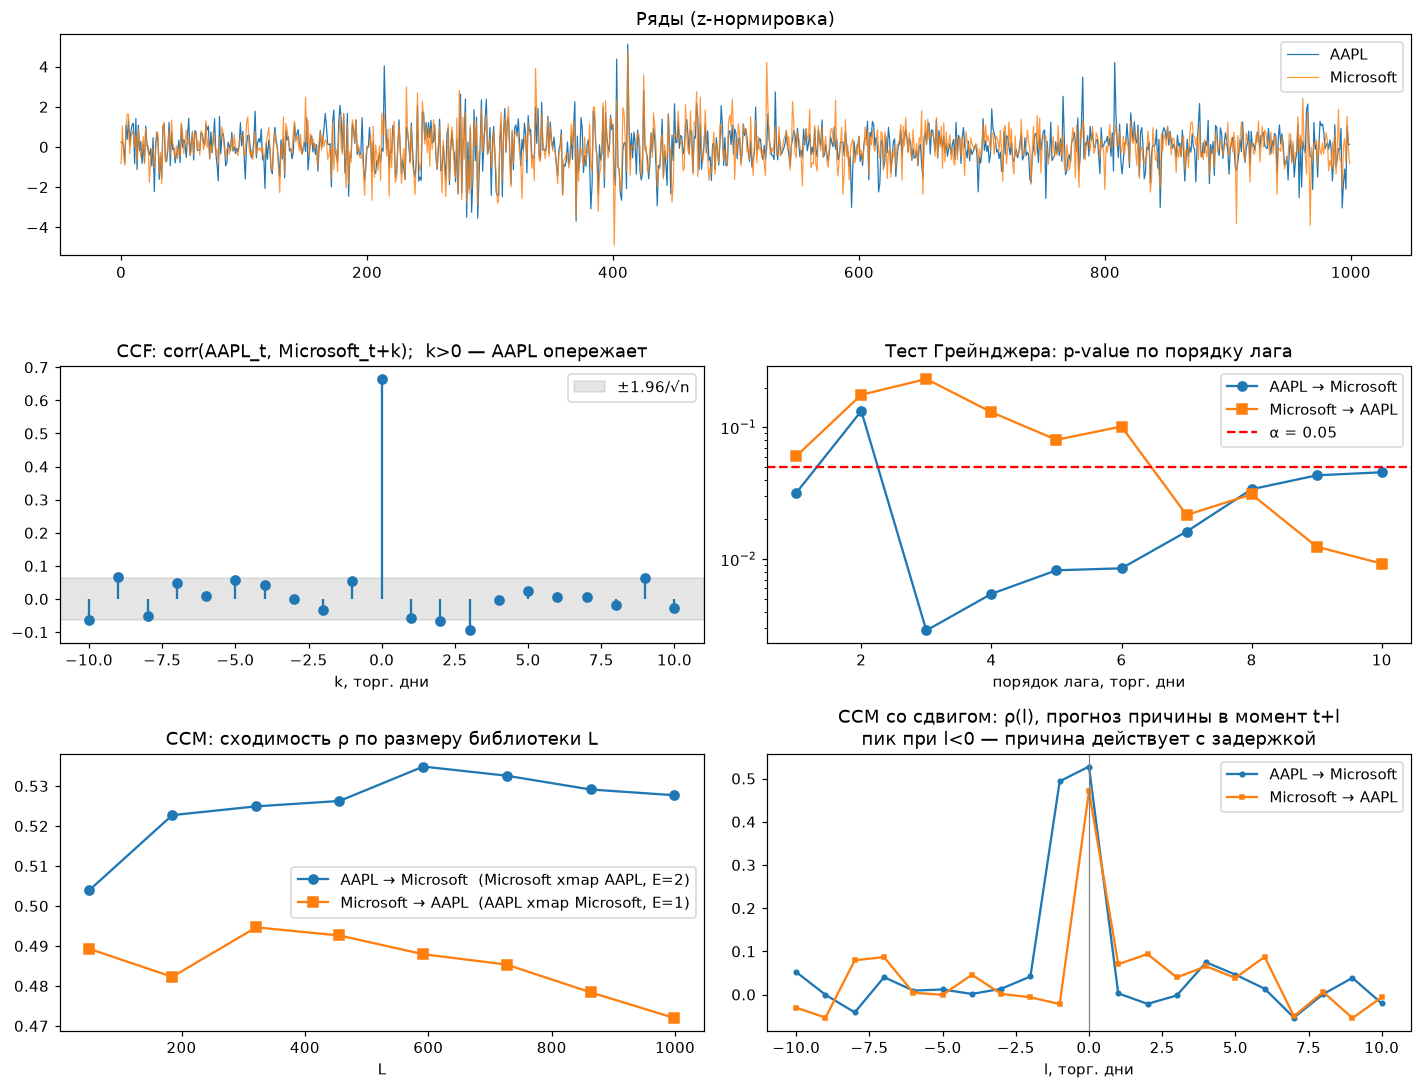

  CCF peak lag: 0
  CCF peak r: 0.665
  Granger AAPL->Microsoft: min p: 0.00288
  Granger AAPL->Microsoft: значимые лаги: [1, 3, 4, 5, 6, 7, 8, 9, 10]
  Granger Microsoft->AAPL: min p: 0.00925
  Granger Microsoft->AAPL: значимые лаги: [7, 8, 9, 10]
  CCM AAPL->Microsoft: rho(Lmin→Lmax): (0.504, 0.528)
  CCM Microsoft->AAPL: rho(Lmin→Lmax): (0.489, 0.472)
  CCM AAPL->Microsoft: лучший сдвиг: 0
  CCM Microsoft->AAPL: лучший сдвиг: 0


In [12]:
res_stock = analyze_pair(r_aapl, r_p, "AAPL", partner[:10], max_lag=10, unit="торг. дни")

* CCF: сильная синхронная связь r(0) = 0.665; при k ≠ 0 |r| < 0.1, почти все значения в доверительной полосе, то есть вчерашняя доходность одной акции практически не предсказывает сегодняшнюю доходность другой
* Грейнджер формально значим в обе стороны на части лагов (min p = 0.003 и 0.009). Но такой же уровень значимости (p = 0.009) получился и для постороннего случайного ряда (ниже). К тому же проверяется 10 вложенных порядков без поправки на множественность, а тяжелые хвосты нарушают предпосылки F-теста. Убедительной направленной связи нет
* CCM: ρ = 0.5 в обе стороны и почти не растет с L (0.50 -> 0.53 и 0.49 -> 0.47), максимум по сдвигу при l = 0. Почти такой же пик ρ ≈ 0.49 при l = −1 для AAPL → MSFT — артефакт вложения: при E = 2 многообразие MSFT содержит MSFT(t−1), синхронно связанную с AAPL(t−1). Это картина синхронной связи, а не причинности

Акции движутся вместе под действием общего фактора (рынок, например), а причинного влияния одной на другую методы не выявляют

corr(уровни AAPL, RW)       = -0.849   <- ложная корреляция
corr(доходности AAPL, ΔRW)  = -0.022
AAPL  vs  RW   (n = 1000)
ADF p-value: AAPL = 0.00e+00,  RW = 0.00e+00


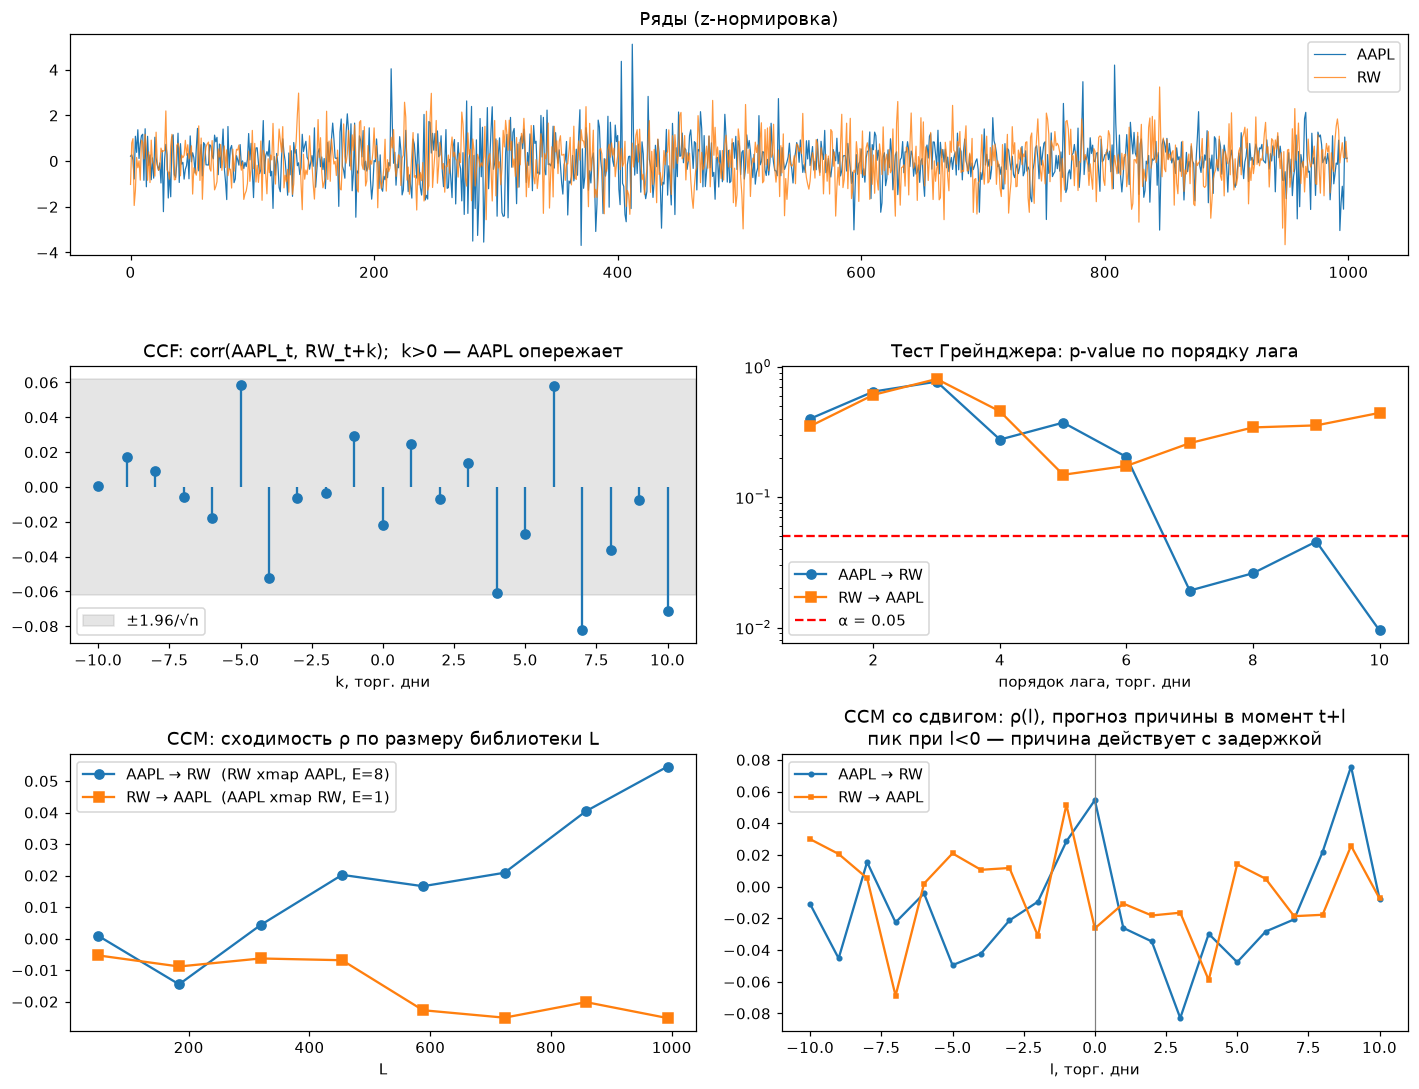

  CCF peak lag: 7
  CCF peak r: -0.082
  Granger AAPL->RW: min p: 0.00949
  Granger AAPL->RW: значимые лаги: [7, 8, 9, 10]
  Granger RW->AAPL: min p: 0.148
  Granger RW->AAPL: значимые лаги: []
  CCM AAPL->RW: rho(Lmin→Lmax): (0.001, 0.055)
  CCM RW->AAPL: rho(Lmin→Lmax): (-0.005, -0.025)
  CCM AAPL->RW: лучший сдвиг: 9
  CCM RW->AAPL: лучший сдвиг: -1


In [13]:
rw = np.cumsum(RNG.normal(size=len(m)))
price = m["Close_aapl"].to_numpy()
print(f"corr(уровни AAPL, RW)       = {np.corrcoef(price, rw)[0, 1]:+.3f}   <- ложная корреляция")
print(f"corr(доходности AAPL, ΔRW)  = {np.corrcoef(r_aapl, np.diff(rw))[0, 1]:+.3f}")

res_rw = analyze_pair(r_aapl, np.diff(rw), "AAPL", "RW", max_lag=10, unit="торг. дни")

* Корреляция уровней цены AAPL и независимого случайного блуждания −0.85, корреляция приращений −0.022.  Классическая ложная регрессия нестационарных рядов
* CCF приращений в пределах полосы, кроме k = 7 (−0.082). Из 21 лага 1–2 выхода за 95 %-полосу ожидаемы случайно.
* Грейнджер дал ложноположительный результат AAPL -> RW на порядках 7–10 (p =0.01). Это прямая иллюстрация проблемы множественных проверок: порядки вложены, и одна случайная корреляция на лаге 7 тянет все последующие
* CCM корректно показывает отсутствие связи: ρ=0 без сходимости.

# Метро Нью-Йорка <-> погода (Open-Meteo, Central Park)

Пассажиропоток почти целиком определяется суточным и недельным циклом, без его удаления любые два ряда с суточным ритмом дают значимую связь. Поэтому:
* метро: ln(поток) минус медиана по часу недели (оценена по всему 2024 г.);
* температура: минус недельное скользящее среднее и средний суточный профиль;
* осадки сдвинуты на 1 ч назад: в Open-Meteo это сумма за предыдущий час с меткой на его конце, а в данных метро час помечается началом

Окно ряда из лаб. работы 1 (последние 1000 ч = 4 окт – 14 ноя 2024) пришлось на рекордно сухую осень, дождливых часов там почти нет, поэтому для осадков окно расширено до 120 суток

In [14]:
idx = pd.date_range("2024-01-01", periods=len(subway), freq="h")
url_w = ("https://archive-api.open-meteo.com/v1/archive?latitude=40.78&longitude=-73.97"
         "&start_date=2024-01-01&end_date=2024-11-14&hourly=temperature_2m,precipitation"
         "&timezone=America%2FNew_York")
with urllib.request.urlopen(url_w) as f:
    meteo = json.load(f)["hourly"]
w = pd.DataFrame(meteo)
w["time"] = pd.to_datetime(w["time"])
w = w.groupby("time").mean().reindex(idx).interpolate(limit_direction="both")  # переходы на летнее время

how = np.asarray(idx.dayofweek * 24 + idx.hour)
log_sub = np.log(subway)
sub_anom = log_sub - pd.Series(log_sub).groupby(how).transform("median").to_numpy()

temp = w["temperature_2m"]
t_res = temp - temp.rolling(24 * 7, center=True, min_periods=1).mean()
temp_anom = (t_res - t_res.groupby(np.asarray(idx.hour)).transform("mean")).to_numpy()
precip = np.log1p(w["precipitation"].shift(-1).ffill().to_numpy())

N, N_RAIN = 1000, 24 * 120
print("Часов с осадками > 0.1 мм: последние 1000 ч —", int((w["precipitation"].to_numpy()[-N:] > 0.1).sum()),
      "| последние 120 сут —", int((w["precipitation"].to_numpy()[-N_RAIN:] > 0.1).sum()))

Часов с осадками > 0.1 мм: последние 1000 ч — 18 | последние 120 сут — 203


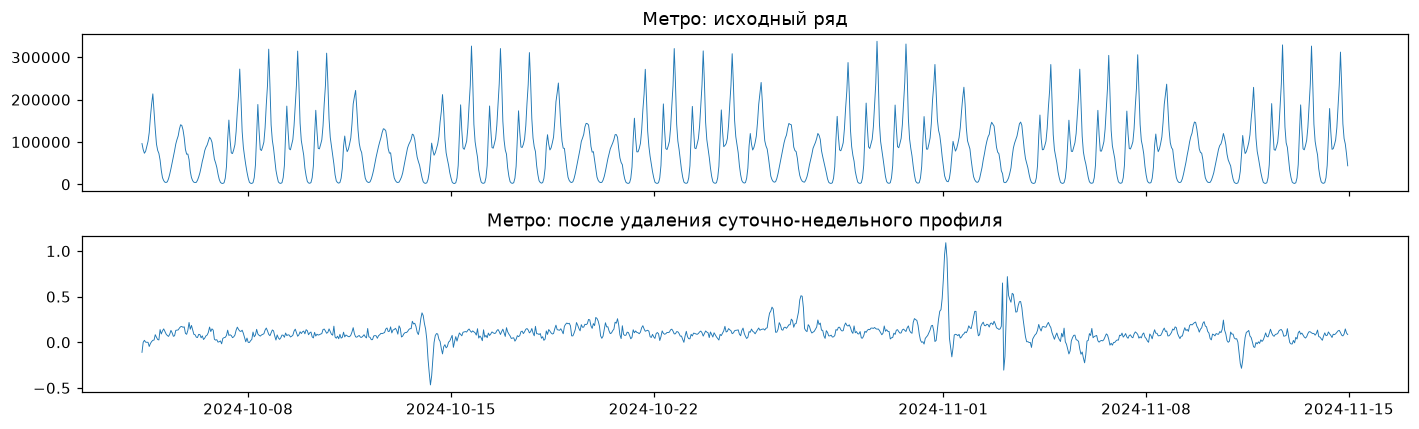

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(13, 4), sharex=True)
ax[0].plot(idx[-N:], subway[-N:], lw=0.6); ax[0].set_title("Метро: исходный ряд")
ax[1].plot(idx[-N:], sub_anom[-N:], lw=0.6); ax[1].set_title("Метро: после удаления суточно-недельного профиля")
plt.tight_layout(); plt.show()

Темп.  vs  Метро   (n = 1000)
ADF p-value: Темп. = 1.37e-04,  Метро = 2.51e-03


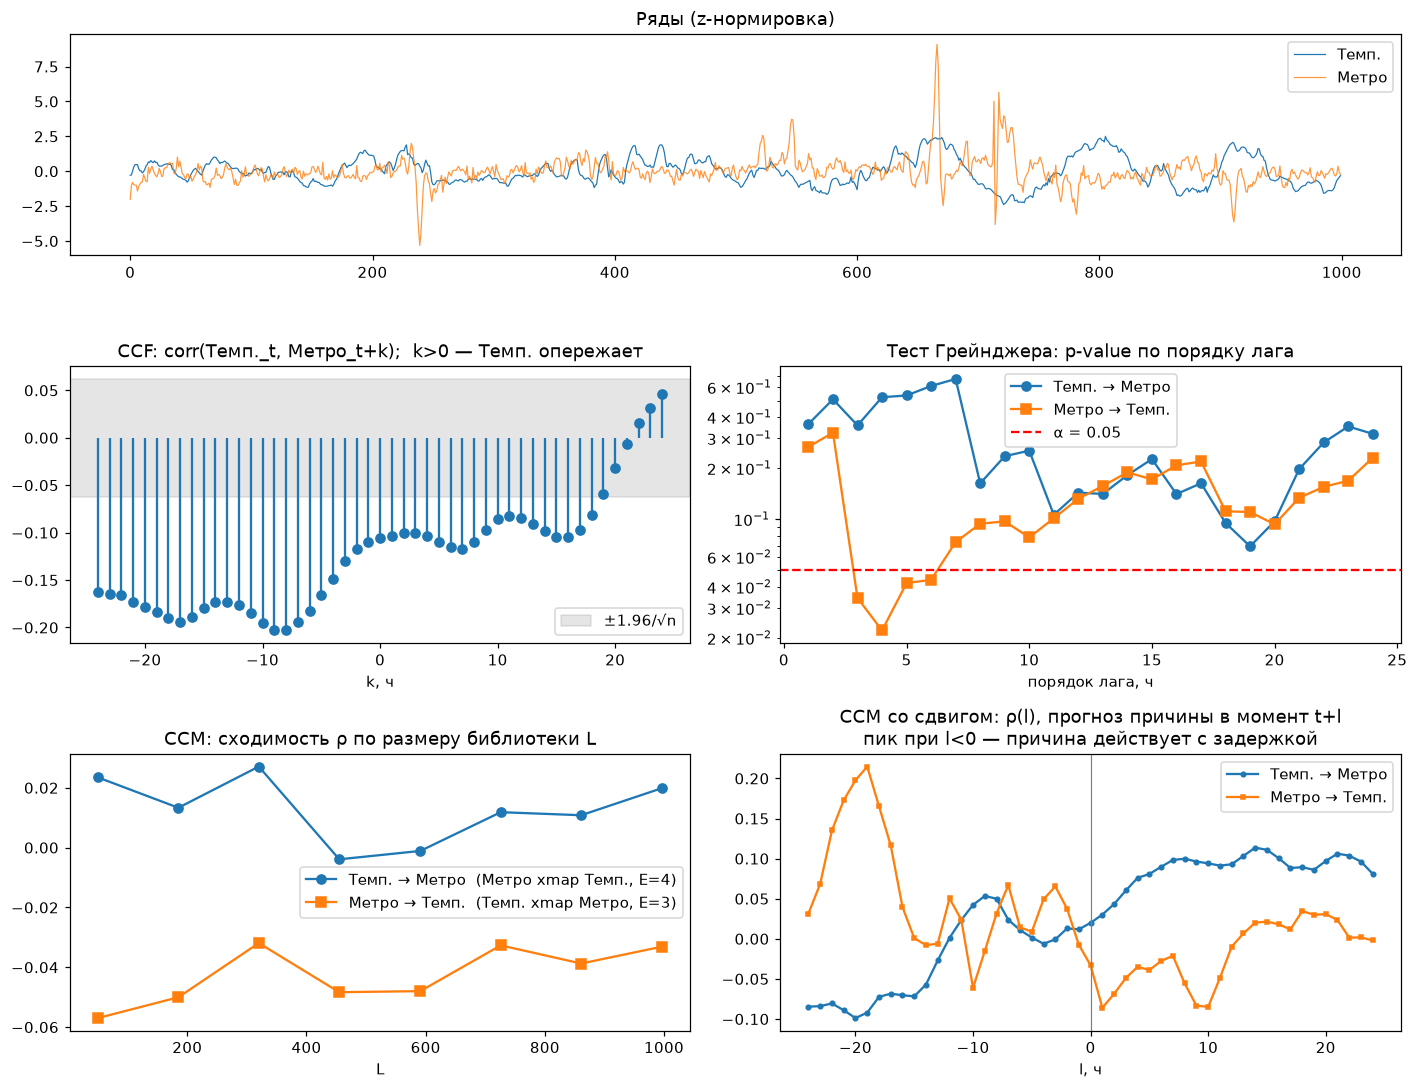

  CCF peak lag: -9
  CCF peak r: -0.203
  Granger Темп.->Метро: min p: 0.0692
  Granger Темп.->Метро: значимые лаги: []
  Granger Метро->Темп.: min p: 0.0221
  Granger Метро->Темп.: значимые лаги: [3, 4, 5, 6]
  CCM Темп.->Метро: rho(Lmin→Lmax): (0.023, 0.02)
  CCM Метро->Темп.: rho(Lmin→Lmax): (-0.057, -0.033)
  CCM Темп.->Метро: лучший сдвиг: 14
  CCM Метро->Темп.: лучший сдвиг: -19


In [16]:
res_temp = analyze_pair(temp_anom[-N:], sub_anom[-N:], "Темп.", "Метро",
                        max_lag=24, exclusion=6, unit="ч")

* В аномалиях пассажиропотока остались события, не связанные с погодой (праздники)
* CCF отрицательна на всех сдвигах (−0.1…−0.2) с максимумом при k = −9 ч, то есть метро опережает температуру. Физически это невозможно, широкая CCF без выраженного пика означает общую медленную компоненту двух автокоррелированных рядов
* Грейнджер: температура -> метро незначимо (min p = 0.07), а невозможное направление метро -> температура значимо на лагах 3–6 ч (p = 0.02). Это ложный результат: при 24 лагах автокорреляция остатков почти учтена, вероятнее его дают общая медленная компонента и выбросы
* CCM: ρ = 0 в обе стороны без сходимости по L. На лаговом графике есть пик ρ = 0.21 при l = −19 ч для метро -> темп. и ρ = 0.1 при l > 0 для темп. -> метро. Первое - физически невозможное направление, второе - антипричинная сторона (l > 0), поэтому оба пика ложные и отражают общую медленную компоненту рядов

Влияние температуры на почасовые отклонения пассажиропотока не обнаружено. Пример хорошо показывает, как формальная значимость появляется в физически невозможном направлении

Осадки  vs  Метро   (n = 2880)
ADF p-value: Осадки = 1.42e-07,  Метро = 1.59e-03


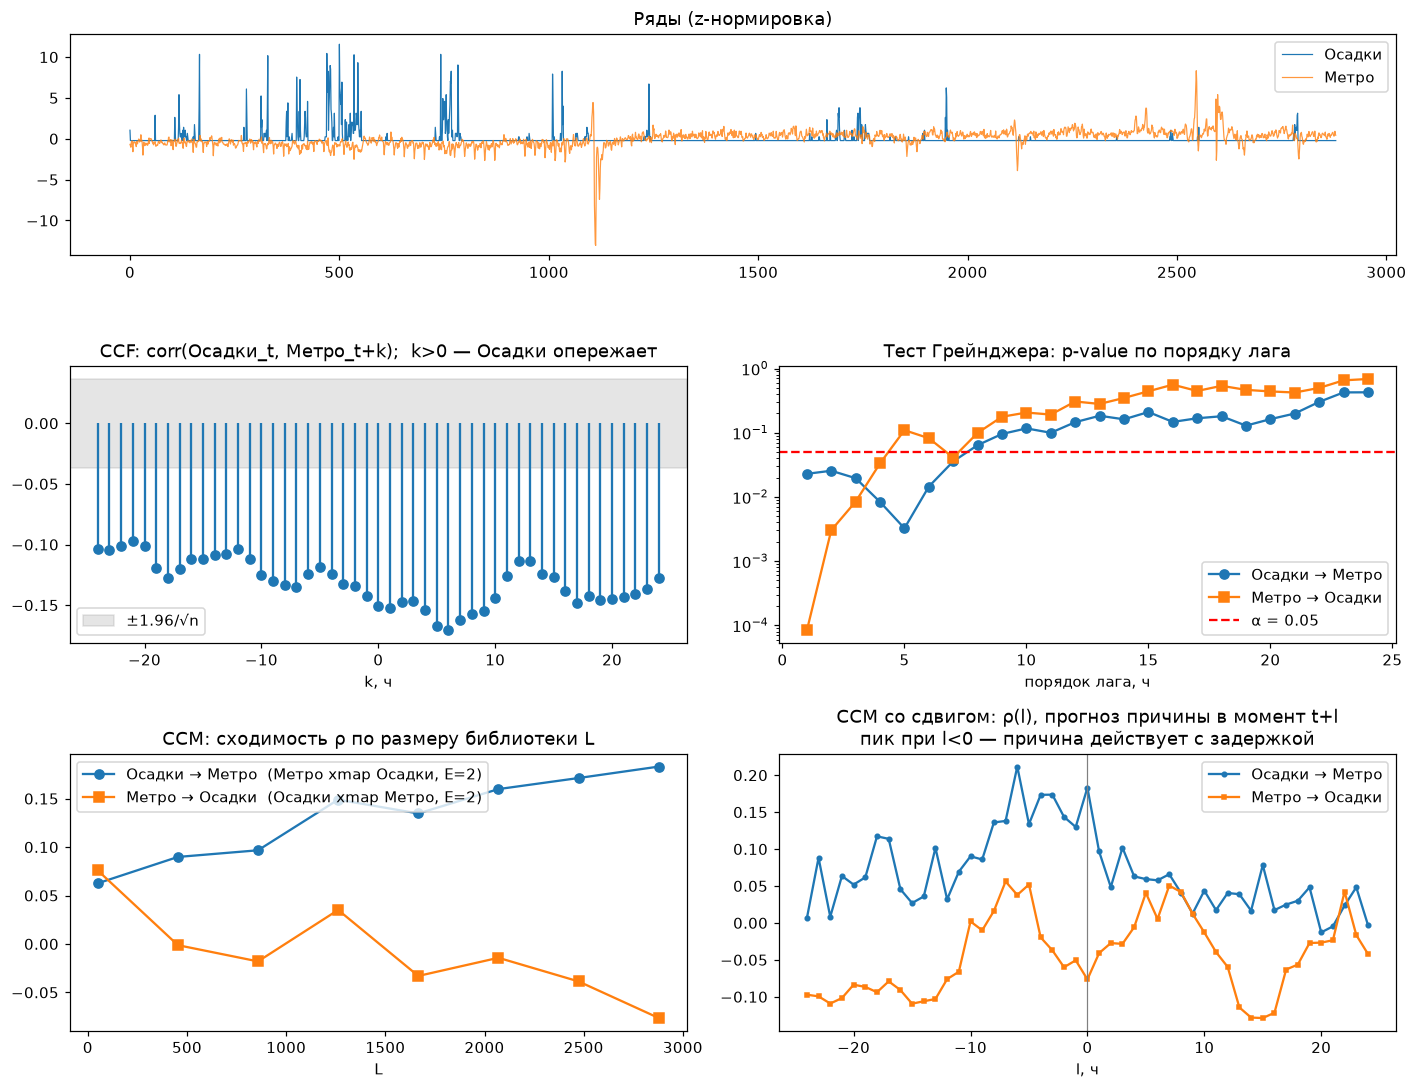

  CCF peak lag: 6
  CCF peak r: -0.171
  Granger Осадки->Метро: min p: 0.00325
  Granger Осадки->Метро: значимые лаги: [1, 2, 3, 4, 5, 6, 7]
  Granger Метро->Осадки: min p: 8.31e-05
  Granger Метро->Осадки: значимые лаги: [1, 2, 3, 4, 7]
  CCM Осадки->Метро: rho(Lmin→Lmax): (0.063, 0.183)
  CCM Метро->Осадки: rho(Lmin→Lmax): (0.076, -0.076)
  CCM Осадки->Метро: лучший сдвиг: -6
  CCM Метро->Осадки: лучший сдвиг: -7


In [17]:
res_rain = analyze_pair(precip[-N_RAIN:], sub_anom[-N_RAIN:], "Осадки", "Метро",
                        max_lag=24, exclusion=6, unit="ч")

* CCF отрицательна на всех сдвигах (−0.10…−0.17). Основная часть этого смещения - сезонный конфаундер. Почти все дождливые часы пришлись на июль–август, когда пассажиропоток ниже среднегодового. Поверх смещения есть минимум при k = 5–6 ч (r = −0.17), то есть возможное снижение потока через несколько часов после дождя
* Грейнджер значим в обе стороны: осадки -> метро на лагах 1–7 (min p = 0.003), метро -> осадки на лагах 1–4 и 7, причем в невозможном направлении сильнее (p = 8e-5 на лаге 1). Согласование меток времени (сдвиг осадков на 1 ч) этот эффект не убрало, значит дело не в разметке часов
* CCM: осадки -> метро ρ растет с L от 0.06 до 0.18, то есть есть сходимость; обратное направление около 0 и убывает с L. Максимум по сдвигу при l = −6 ч согласуется с минимумом CCF при k = 6

Есть слабый, но согласованный по CCF и CCM признак, что дождь снижает пассажиропоток с задержкой около 6 ч. Величина эффекта мала, возможно, сезонность ее искажает

# ЭКГ: частота сердечных сокращений <-> дыхание (канал RESP той же записи)

Сырой фрагмент ЭКГ из лаб. работы 1 (1600 отсчетов = 6.4 с) слишком короткий для анализа причинности, а сам сигнал ЭКГ с дыханием напрямую не сопоставим. Поэтому из той же записи и с того же места берем 5 минут, по R-пикам строим мгновенную ЧСС и переводим ее и дыхание на сетку 4 Гц. Физиологически ожидается, что на вдохе ЧСС растет, т.е. дыхание -> ЧСС

In [18]:
resp_full = record.p_signal[:, [i for i, s in enumerate(record.sig_name) if "RESP" in s.upper()][0]]
DUR, FS_NEW = 5 * 60, 4
seg = slice(start_idx, start_idx + int(DUR * FS))

try:
    r_all = wfdb.rdann(str(FANTASIA_DIR / "f1y01"), "ecg").sample
except Exception:
    from wfdb import processing
    r_all = processing.xqrs_detect(ecg_full, fs=FS, verbose=False)
r = r_all[(r_all >= seg.start - 5 * FS) & (r_all < seg.stop + 5 * FS)] / FS
rr, t_beat = np.diff(r), (r[:-1] + r[1:]) / 2
ok = (rr > 0.3) & (rr < 2.0)

t_grid = np.arange(seg.start, seg.stop, FS / FS_NEW) / FS
hr = detrend(np.interp(t_grid, t_beat[ok], 60 / rr[ok]))
fr = Fraction(FS_NEW, int(FS))
resp = resample_poly(resp_full[seg], fr.numerator, fr.denominator, padtype="line")
n_ = min(len(hr), len(resp)); hr, resp = hr[:n_], resp[:n_]
print(f"Отсчетов: {n_}, средняя ЧСС: {np.mean(60 / rr[ok]):.1f} уд/мин")

Отсчетов: 1200, средняя ЧСС: 78.4 уд/мин


RESP  vs  HR   (n = 1200)
ADF p-value: RESP = 2.13e-10,  HR = 9.82e-06


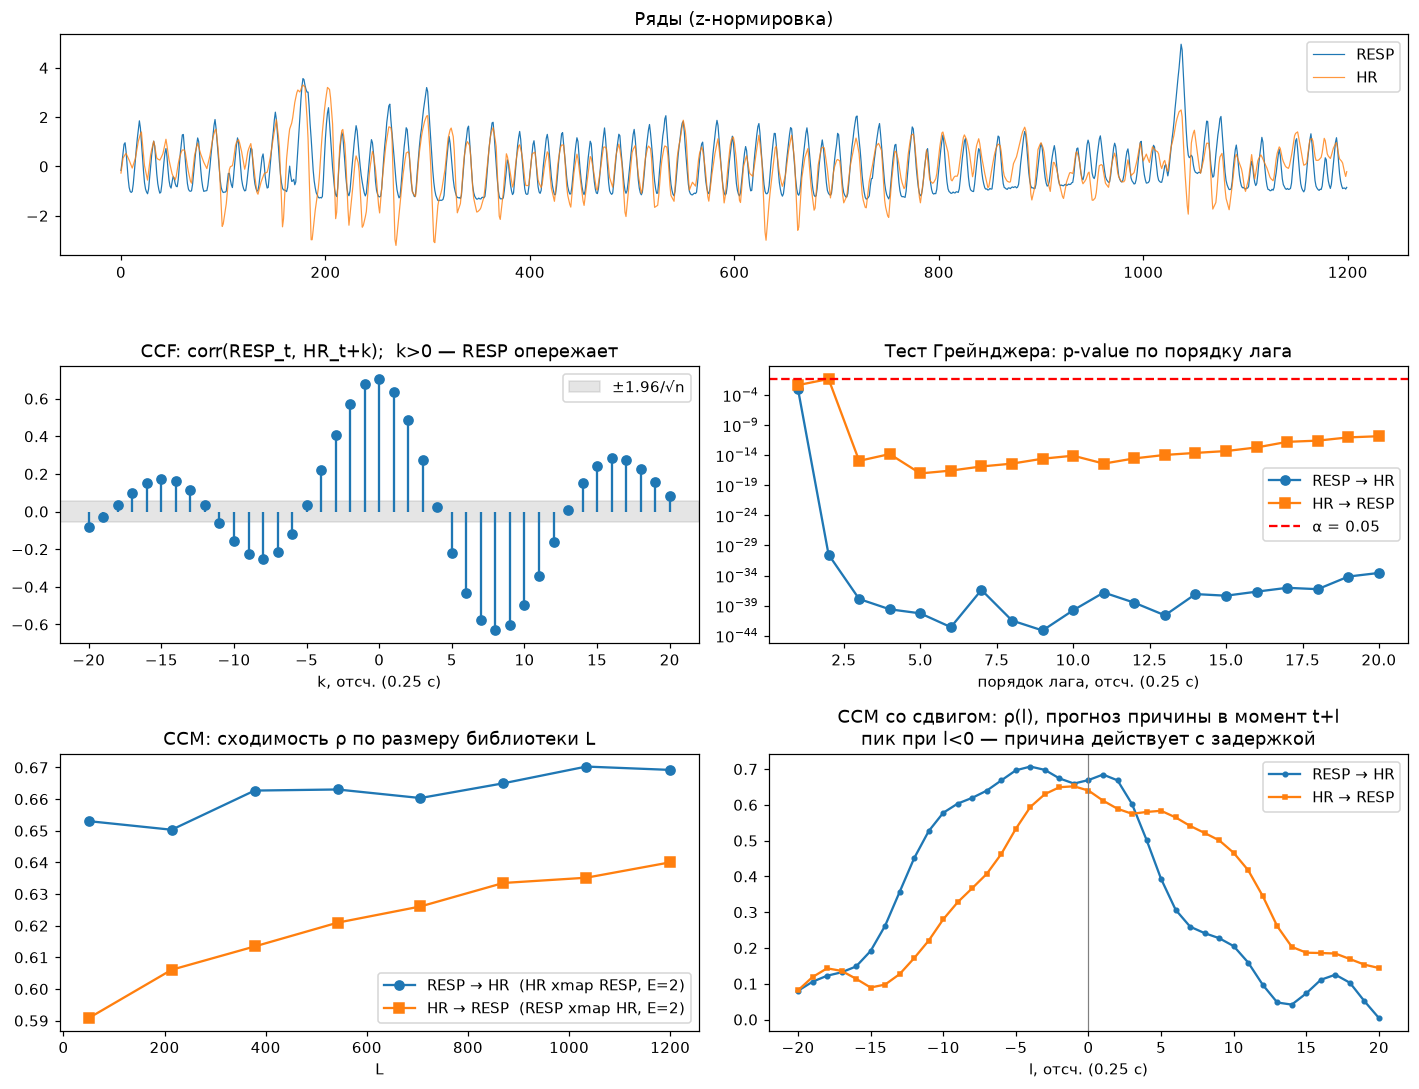

  CCF peak lag: 0
  CCF peak r: 0.704
  Granger RESP->HR: min p: 7.45e-44
  Granger RESP->HR: значимые лаги: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
  Granger HR->RESP: min p: 9.54e-18
  Granger HR->RESP: значимые лаги: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
  CCM RESP->HR: rho(Lmin→Lmax): (0.653, 0.669)
  CCM HR->RESP: rho(Lmin→Lmax): (0.591, 0.64)
  CCM RESP->HR: лучший сдвиг: -4
  CCM HR->RESP: лучший сдвиг: -1


In [19]:
res_hr = analyze_pair(resp, hr, "RESP", "HR", max_lag=20, exclusion=4, unit="отсч. (0.25 с)")

* CCF колебательная с периодом около 16 отсчетов = 4 с (15 вдохов/мин). Главный пик r = 0.70 при k = 0: после привязки ЧСС к середине RR-интервала запаздывания на сетке 0.25 с не видно
* Грейнджер значим в обе стороны на всех 20 лагах, но асимметрично: RESP -> HR min p = 1e-44, HR -> RESP min p = 1e-17. Значимость в обратную сторону ожидаема, так ка оба ряда почти периодические с общей частотой, и прошлое ЧСС содержит фазу дыхания
* CCM: ρ высокий в обе стороны. RESP -> HR выше по величине (0.65 -> 0.67), но почти не растет с L; HR -> RESP ниже, но растет заметнее (0.59 -> 0.64). Это картина синхронизации при сильной периодической связи, где сходимость CCM направление не различает
* Лаговый CCM: для RESP -> HR максимум ρ = 0.70 при l = −4 (1 с), то есть за пределами окна вложения (E−1)τ = 1. Это соответствует направлению дыхание -> ЧСС с задержкой около 1 с. Но второй пик при l = +1 почти такой же (0.69), а максимум HR -> RESP при l = −1 попадает в окно вложения и не интерпретируется, поэтому аргумент слабый

Направление дыхание -> ЧСС поддерживают асимметрия теста Грейнджера и, слабо, лаговый CCM, а CCF и сходимость CCM показывают двустороннюю связь. Это согласуется с дыхательной синусовой аритмией, единственной парой с известной физиологической причинностью

**Общие выводы по части 1.**
* Кросс-корреляция показывает только ассоциацию и запаздывание. Общий фактор (рынок), общая сезонность (лето и дожди) или общая медленная компонента дают связь без причинности
* Тест Грейнджера чувствителен к нестационарности, выбросам и множественным проверкам. Он дал ложноположительные результаты в контроле со случайным рядом и в физически невозможных направлениях (метро -> погода)
* CCM корректно отделил отсутствие связи: для случайного ряда и для температуры ρ=0 без сходимости. Но синхронная связь через общий фактор (AAPL–MSFT, ρ ≈ 0.5 в обе стороны) дает высокий ρ и без причинности, а при сильной периодической связи (дыхание–ЧСС) ρ высокий и растет с L в обе стороны. По сходимости направление здесь не определяется; лаговый CCM дает лишь слабый аргумент в пользу RESP -> HR. Для осадков -> метро CCM дал слабую, но сходящуюся связь с задержкой около 6 ч, согласованную с CCF

Надежный вывод о причинности можно сделать только при согласии методов между собой и с предметным знанием. Полностью этого не произошло ни в одном эксперименте. Для пары дыхание -> ЧСС направление поддерживают асимметрия теста Грейнджера, слабо лаговый CCM и физиология (дыхательная синусовая аритмия), а CCF и сходимость CCM показывают только сильную двустороннюю связь. Для осадков -> метро согласуются CCF и CCM, но эффект слабый и искажен сезонностью

# Dynamic Time Warping на ЭКГ MIT-BIH

Предобработка: полосовой фильтр 0.5–40 Гц (убирает дрейф изолинии), z-нормировка, прореживание до 180 Гц

In [20]:
mit_path = kagglehub.dataset_download("mondejar/mitbih-database")
FS_MB, DOWN = 360, 2
bf, af = butter(3, [0.5, 40], btype="band", fs=FS_MB)

In [21]:
def load_mitbih(rec, lead="MLII"):
    f = next(Path(mit_path).rglob(f"{rec}.csv"))
    df = pd.read_csv(f)
    df.columns = [c.strip().strip("'").strip() for c in df.columns]
    return zscore(filtfilt(bf, af, df[lead].to_numpy(float)))

sig = {rec: load_mitbih(rec) for rec in ("100", "117")}
BEATS = set("NLRBAaJSVrFejnE/fQ")

def ann_peaks(rec):
    f = next(Path(mit_path).rglob(f"{rec}annotations.txt"))
    rows = [l.split() for l in open(f).read().splitlines()[1:]]
    return np.array([int(r[1]) for r in rows if len(r) > 2 and r[2] in BEATS])

peaks = {rec: ann_peaks(rec) for rec in sig}
for rec in sig:
    print(f"{rec}: средний RR = {np.mean(np.diff(peaks[rec])) / FS_MB:.2f} с")

100: средний RR = 0.79 с
117: средний RR = 1.18 с


In [22]:
def cycle(rec, k, pre=0.3):
    """Один сердечный цикл: от (R_k − pre) до (R_{k+1} − pre)."""
    p, s = peaks[rec], int(pre * FS_MB)
    return zscore(sig[rec][p[k] - s:p[k + 1] - s][::DOWN])

def fragment(rec, t0, dur):
    return zscore(sig[rec][int(t0 * FS_MB):int((t0 + dur) * FS_MB)][::DOWN])

In [23]:
def plot_dtw(a, b, fs, la, lb, window=None, step=6, title=""):
    """4 панели: исходные ряды, матрица стоимостей с путем, соответствия точек, ряд b после выравнивания."""
    d, path, C, _ = dtw(a, b)
    ta, tb = np.arange(len(a)) / fs, np.arange(len(b)) / fs
    m = max(len(a), len(b))
    res = lambda s: np.interp(np.linspace(0, 1, m), np.linspace(0, 1, len(s)), s)
    eu = np.sqrt(((res(a) - res(b)) ** 2).sum())

    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle(title, fontsize=13)
    ax[0, 0].plot(ta, a, label=f"{la} ({len(a)/fs:.2f} c)")
    ax[0, 0].plot(tb, b, label=f"{lb} ({len(b)/fs:.2f} c)")
    ax[0, 0].set_title("Исходные ряды"); ax[0, 0].set_xlabel("t, с"); ax[0, 0].legend()

    ax[0, 1].imshow(C, origin="lower", aspect="auto", cmap="viridis",
                    extent=[0, tb[-1], 0, ta[-1]])
    ax[0, 1].plot([0, tb[-1]], [0, ta[-1]], "w:", lw=1, label="диагональ (без деформации)")
    ax[0, 1].plot(tb[path[:, 1]], ta[path[:, 0]], "r", lw=1.5, label=f"DTW, D = {d:.1f}")
    if window is not None:
        d_w, path_w, _, _ = dtw(a, b, window)
        ax[0, 1].plot(tb[path_w[:, 1]], ta[path_w[:, 0]], "c--", lw=1.5,
                      label=f"DTW, полоса {max(window, abs(len(a) - len(b))) / fs:.2f} с, D = {d_w:.1f}")
    ax[0, 1].set_xlabel(f"t {lb}, с"); ax[0, 1].set_ylabel(f"t {la}, с")
    ax[0, 1].set_title("Матрица (a_i − b_j)² и путь деформации"); ax[0, 1].legend(fontsize=8, loc="lower right")

    off = 1.2 * (np.ptp(a) + np.ptp(b)) / 2
    ax[1, 0].plot(ta, a + off, label=la); ax[1, 0].plot(tb, b, label=lb)
    for i, j in path[::step]:
        ax[1, 0].plot([ta[i], tb[j]], [a[i] + off, b[j]], color="gray", lw=0.4, alpha=0.6)
    ax[1, 0].set_title("Соответствие точек (каждая %d-я пара пути)" % step)
    ax[1, 0].set_xlabel("t, с"); ax[1, 0].set_yticks([]); ax[1, 0].legend()

    cnt = np.bincount(path[:, 0], minlength=len(a))
    b_on_a = np.bincount(path[:, 0], weights=b[path[:, 1]], minlength=len(a)) / cnt
    ax[1, 1].plot(ta, a, label=la)
    ax[1, 1].plot(ta, b_on_a, "--", label=f"{lb}, перенесенный на шкалу {la}")
    ax[1, 1].set_title(f"После выравнивания: евклид = {eu:.1f}  →  DTW = {d:.1f}")
    ax[1, 1].set_xlabel(f"t {la}, с"); ax[1, 1].legend()
    plt.tight_layout(); plt.show()
    return d, eu

Пара 1: по одному сердечному циклу разной длительности

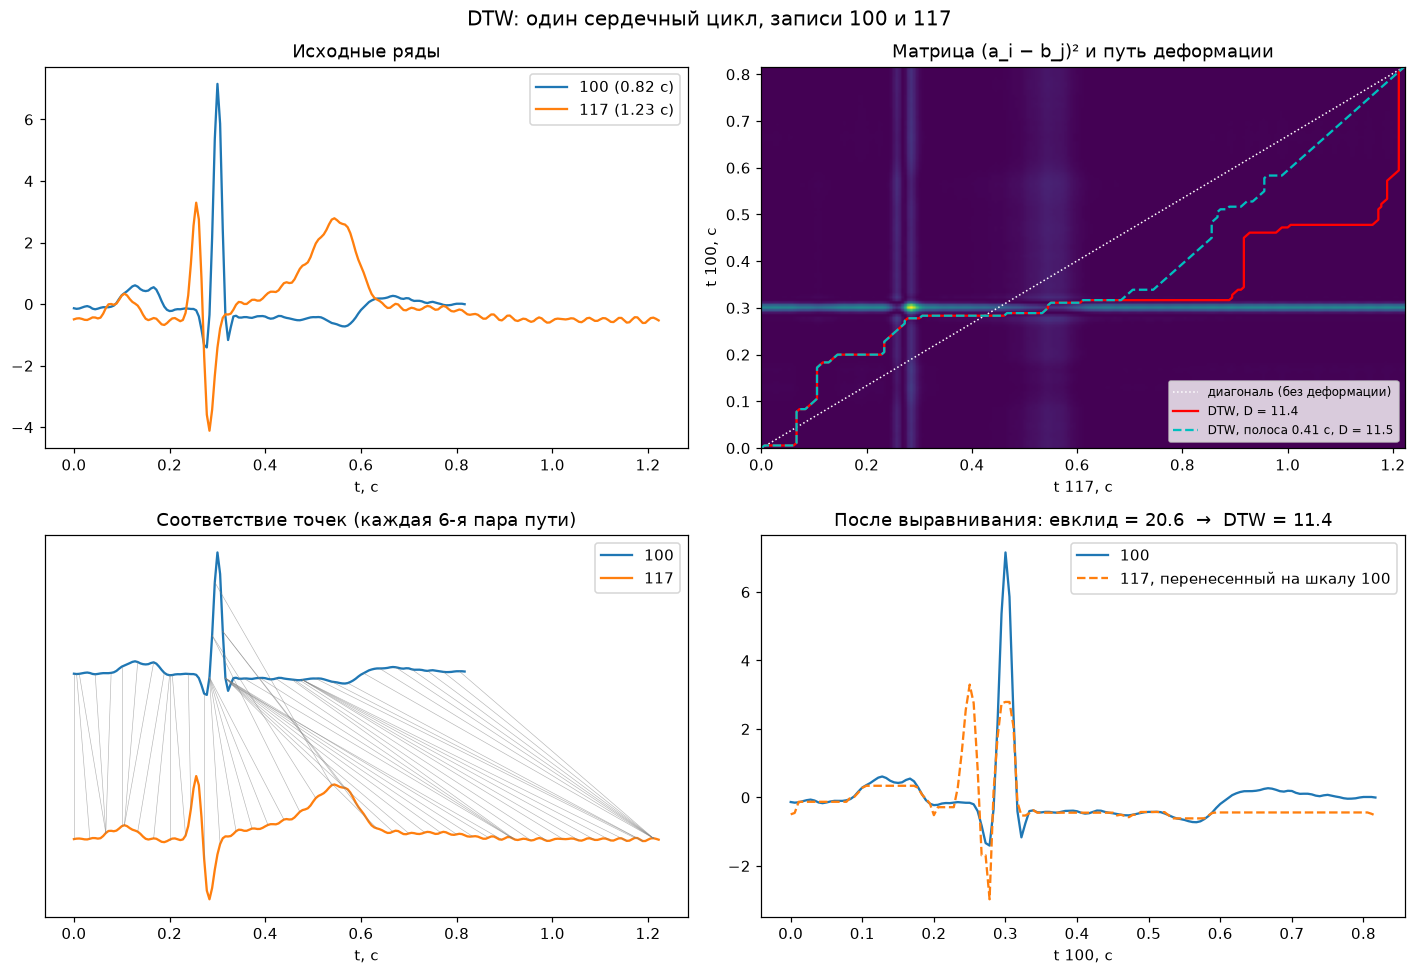

(np.float64(11.380958447042559), np.float64(20.551888325964732))

In [24]:
fs_ = FS_MB / DOWN
a, b = cycle("100", 20), cycle("117", 20)
plot_dtw(a, b, fs_, "100", "117", window=int(0.1 * fs_),
         title="DTW: один сердечный цикл, записи 100 и 117")

Циклы имеют длительность 0.82 с (запись 100) и 1.23 с (запись 117). DTW верно сопоставил начало цикла (P-волну и интервал PR), но дальше выравнивание физиологически неверное. У записи 100 главный пик (R-зубец) один и очень высокий (7 после z-нормировки), а остальные волны малы. У записи 117 R-зубец вдвое ниже (3.3), сразу за ним идет глубокий провал (S-зубец, −4), а волна T после комплекса почти такой же высоты, как R (2.8). То есть в цикле 117 два пика сопоставимой высоты, и по одним значениям DTW не может отличить, какой из них соответствует R-пику записи 100. Поэтому R-пику записи 100 DTW сопоставил T-зубец записи 117 (горизонтальный участок),а QRS записи 117 оказался сопоставлен участку перед R-пиком записи 100. Малый T-зубец записи 100 сопоставлен изолинии TP записи 117. Расстояние уменьшилось с 20.6 (евклид) до 11.4, но за счет неверного соответствия: DTW выравнивает значения, а не смысловые элементы сигнала, и при разном строении комплексов у разных пациентов сопоставляет между собой самые крупные пики. Для рядов разной длины окно автоматически расширяется до |n−m| = 0.41 с, поэтому полоса почти не ограничивает путь (D = 11.5). Улучшить выравнивание можно, сравнивая производные вместо значений (derivative DTW): у QRS крутые фронты, у T-зубца пологие

Пара 2: фрагменты по 3 с, разное число ударов

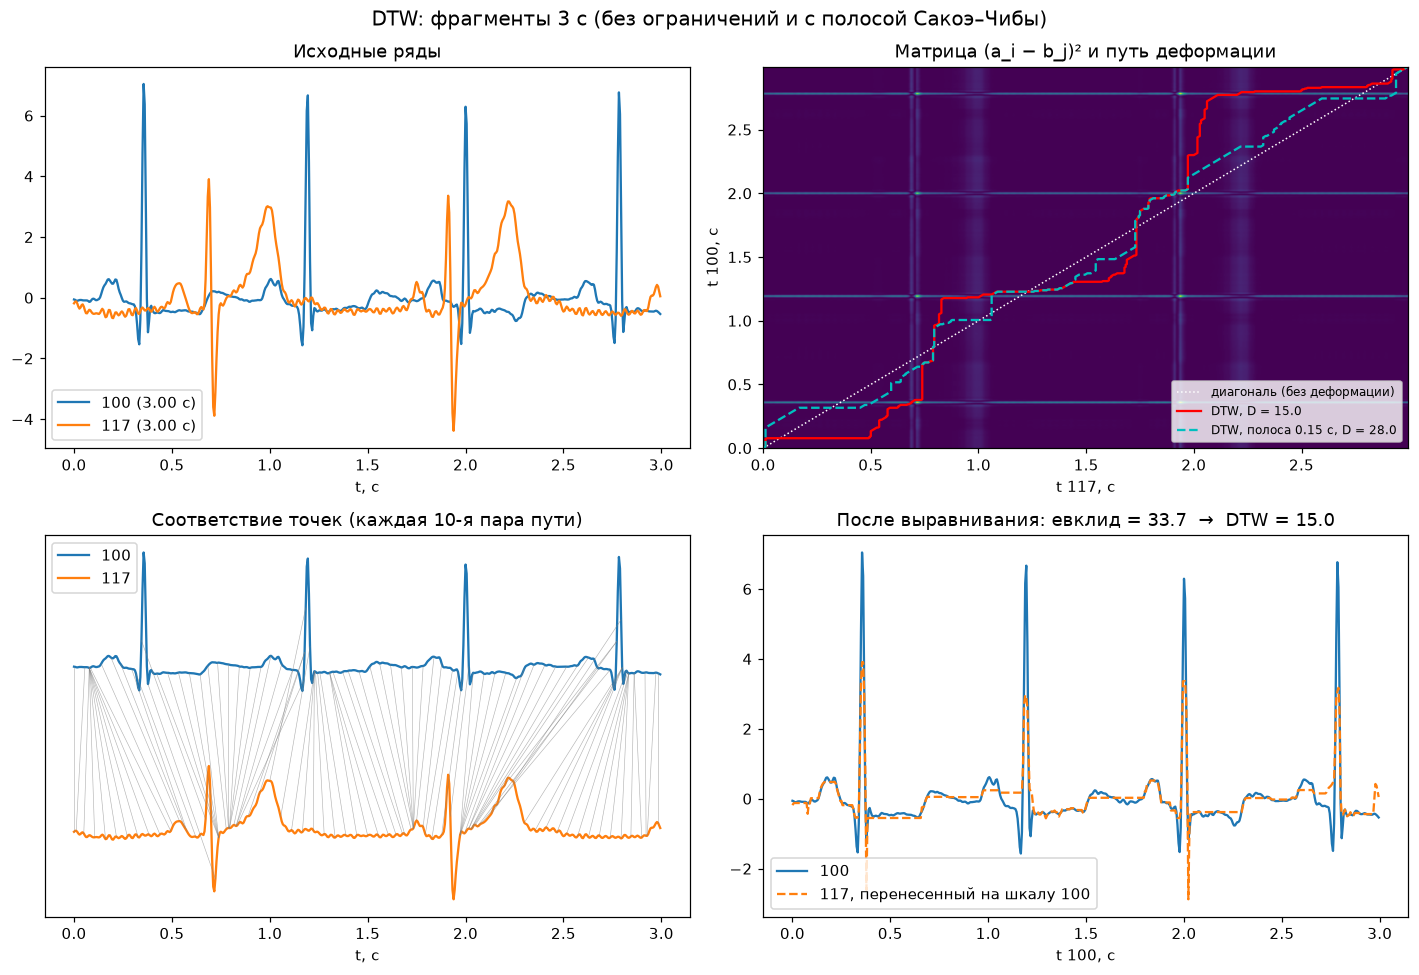

(np.float64(15.045725386408565), np.float64(33.726212138103364))

In [25]:
a, b = fragment("100", 60, 3), fragment("117", 60, 3)
plot_dtw(a, b, fs_, "100", "117", window=int(0.15 * fs_), step=10,
         title="DTW: фрагменты 3 с (без ограничений и с полосой Сакоэ–Чибы)")

Во фрагменте записи 100 четыре удара, во фрагменте записи 117 два. Без ограничений DTW снижает расстояние с 33.7 (евклид) до 15.0, но за счет сингулярностей: длинные горизонтальные и вертикальные участки пути означают, что одна точка одного ряда растягивается на десятки-сотни отсчетов другого (до около 0.8 с). На правом нижнем графике у перенесенного ряда 117 четыре пика: четырем R-пикам записи 100 сопоставлены два QRS и два T-зубца записи 117, то есть та же ошибка, что и на одиночном цикле. Полоса Сакоэ–Чибы 0.15 с (ряды одной длины, поэтому окно не расширяется) запрещает такие деформации, и расстояние растет до 28.0

Пара 3: два цикла одной записи с разным RR

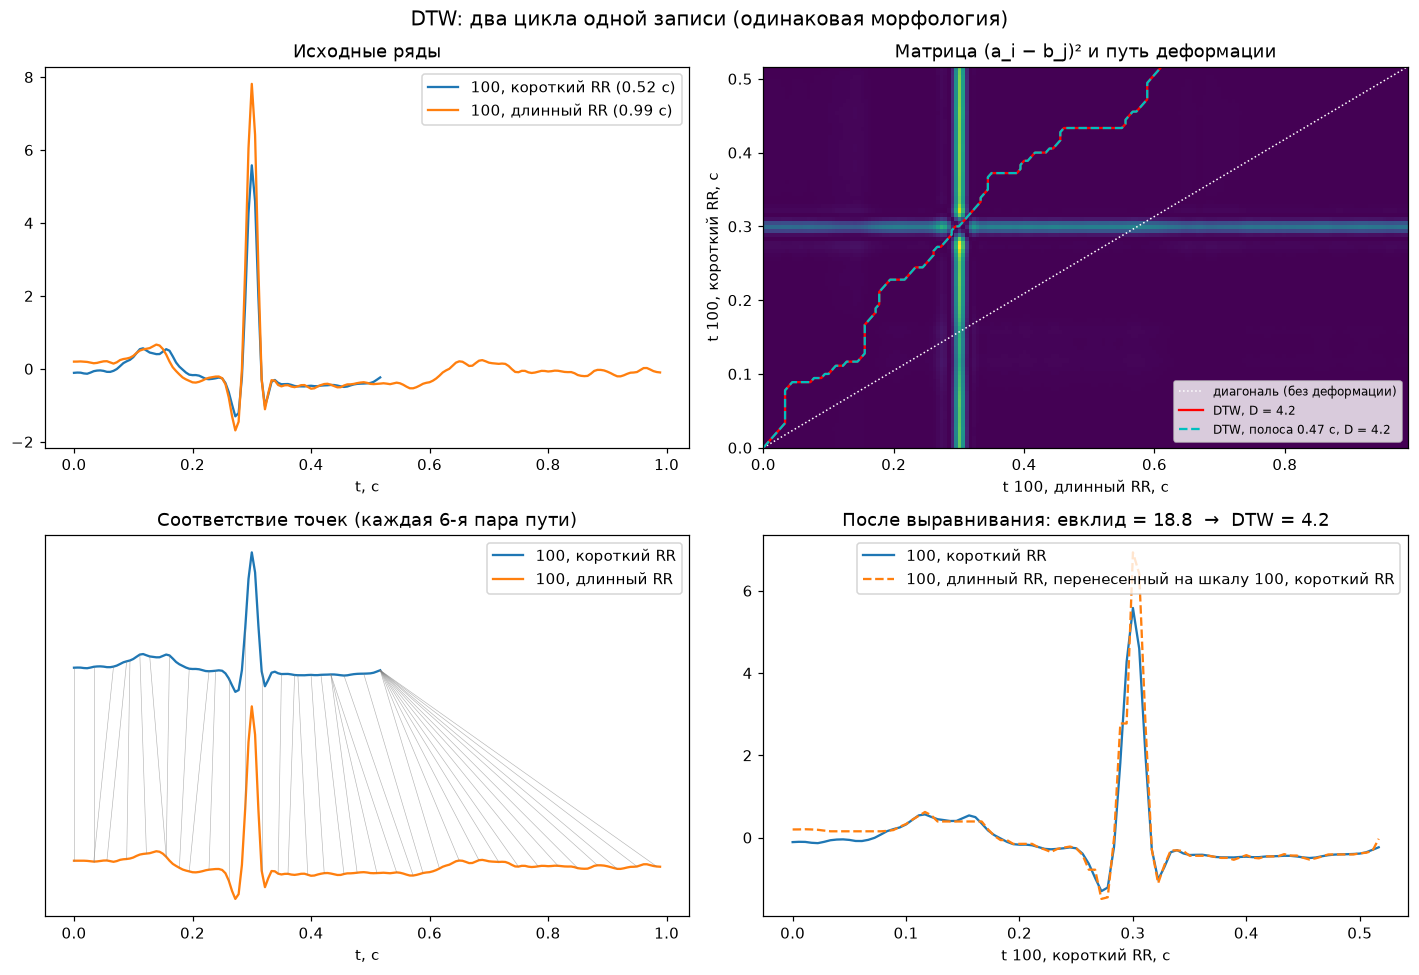

Тип удара после короткого RR: A


In [26]:
rr100 = np.diff(peaks["100"])[1:300]
ks, kl = rr100.argmin() + 1, rr100.argmax() + 1
a, b = cycle("100", ks), cycle("100", kl)
plot_dtw(a, b, fs_, "100, короткий RR", "100, длинный RR", window=int(0.1 * fs_),
         title="DTW: два цикла одной записи (одинаковая морфология)")
f = next(Path(mit_path).rglob("100annotations.txt"))
sym = [r[2] for r in (l.split() for l in open(f).read().splitlines()[1:]) if len(r) > 2 and r[2] in BEATS]
print("Тип удара после короткого RR:", sym[ks + 1])  # A — предсердная экстрасистола, N — норма

Циклы одной записи длительностью 0.52 с и 0.99 с. DTW: P-волны и QRS сопоставлены друг другу, R-пики совпадают по времени (0.30 с на обеих осях), и после выравнивания ряды почти неотличимы. Расстояние падает с 18.8 (евклид после линейного растяжения) до 4.2. Линейное растяжение сдвигает QRS короткого цикла относительно длинного, а DTW деформирует шкалу нелинейно (участок до R почти не растягивается, а вся разница длительностей приходится на конец цикла). Короткий цикл обрывается до T-зубца, поэтому T-зубец и интервал TP длинного цикла (0.6–0.99 с) сопоставлены последней точке короткого - это сингулярность, но здесь она отражает реальное отсутствие участка, а не ошибку. Полоса автоматически расширяется до |n−m| = 0.47 с, поэтому путь с ограничением совпадает с исходным (D = 4.2)

**Вывод по части 2**

DTW хорошо выравнивает ряды с одинаковой формой и разной длительностью (пара 3): он компенсирует нелинейные изменения темпа, которые не исправить линейным растяжением. При разном строении (записи 100 и 117, пары 1–2) DTW по-прежнему уменьшает расстояние, но за счет физиологически неверных соответствий и сингулярностей. Поэтому малое DTW-расстояние само по себе не означает похожие сигналы. Полоса Сакоэ–Чибы ограничивает патологические деформации, но при сильно разной длине рядов автоматически расширяется и почти перестает действовать